# RoadScan: YOLO26n + SAHI evaluation (Google Colab)

Use your existing 20-epoch best weights. **This notebook contains no training calls.**
It compares standard detection with tiled detection, tunes confidence on validation only,
freezes the choice, and evaluates both methods on RDD and Saudi tests.

Previous test results: RDD mAP50 49.60%, mAP50-95 22.99%; Saudi mAP50 19.50%,
mAP50-95 8.15%. Saudi recall was low, especially for longitudinal cracks.
SAHI may recover small defects, but can add false positives and latency.
Existing 512/640 exports have already lost detail; tiling cannot restore it.

Run cells in order. CPU is the default to preserve Colab GPU quota; GPU is optional
for inference only. Validation and test predictions are cached on Drive.
The small candidate screen is followed by full validation. No improvement is assumed.
The existing Saudi test has already been inspected; a new independent road-level test
will be needed for an unbiased future deployment claim.


In [1]:
%pip install -q "ultralytics==8.4.183" "sahi==0.11.36" pandas matplotlib pyyaml pillow tqdm


In [2]:
import os, json, time, hashlib, shutil, zipfile, random, platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch, yaml, ultralytics, sahi
from ultralytics import YOLO
from ultralytics.utils.metrics import ap_per_class
from sahi import AutoDetectionModel
from sahi.predict import get_sliced_prediction
from tqdm.auto import tqdm
from IPython.display import display
from google.colab import drive
drive.mount('/content/drive')
assert ultralytics.__version__ == '8.4.183', 'Restart the runtime after installation.'


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Mounted at /content/drive


## 1. Paths and fixed experiment settings
The weights are loaded from your existing session if available, otherwise from your
deployment ZIP. Set the ZIP path if it is stored elsewhere. No images are uploaded to
an external inference service. Keep the output directory unchanged to reuse caches.


In [3]:
BASE = Path('/content/drive/MyDrive/RoadScan_P')
DATA_SOURCE = BASE/'RoadScan_RDD_SaudiRD2_Validated.zip'
WEIGHTS_SOURCE = BASE/'RoadScan_Professional_Results/yolo26n_640_20epochs/training/yolo26n_640/weights/best.pt'
DEPLOYMENT_ZIP = BASE/'RoadScan_Improved_Deployment.zip'
OUTPUT = BASE/'RoadScan_SAHI_Evaluation'
LOCAL = Path('/content/roadscan_sahi')
DEVICE = 'cpu'  # Change to 'cuda:0' only for optional GPU inference.
SEED, IMGSZ, MAX_DET, NMS_IOU = 42, 640, 300, 0.6
CONF_FLOOR = 0.001  # AP uses low-confidence predictions, not deployment thresholds.
IOU_LEVELS = np.linspace(0.5, 0.95, 10)
THRESHOLD_GRID = np.round(np.arange(0.05, 0.81, 0.01), 2)
SCREEN_IMAGES = 80
CLASS_NAMES = ['longitudinal_crack', 'transverse_crack', 'alligator_crack', 'pothole']
CODES = ['D00', 'D10', 'D20', 'D40']
NC = len(CODES)
METHODS = {
    'standard': {'tile': None},
    'sahi_384': {'tile': 384},
    'sahi_512': {'tile': 512},
}
OVERLAP = 0.2
EXCLUDE_EMPTY_SAUDI = True  # Preserve the existing 77-image protocol; log exclusions.
for folder in [OUTPUT, LOCAL]: folder.mkdir(parents=True, exist_ok=True)
torch.set_num_threads(min(4, os.cpu_count() or 1))
if DEVICE != 'cpu': assert torch.cuda.is_available(), 'Choose a GPU runtime or use CPU.'

def save_json(path, obj):
    path=Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    temp=path.with_suffix(path.suffix+'.tmp')
    temp.write_text(json.dumps(obj, indent=2, allow_nan=False), encoding='utf-8')
    temp.replace(path)

def file_hash(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as f:
        for chunk in iter(lambda: f.read(1024*1024), b''): h.update(chunk)
    return h.hexdigest()

WEIGHTS=LOCAL/'roadscan_best.pt'
if WEIGHTS_SOURCE.is_file():
    shutil.copy2(WEIGHTS_SOURCE, WEIGHTS)
else:
    assert DEPLOYMENT_ZIP.is_file(), f'Set WEIGHTS_SOURCE or DEPLOYMENT_ZIP: {DEPLOYMENT_ZIP}'
    with zipfile.ZipFile(DEPLOYMENT_ZIP) as z:
        WEIGHTS.write_bytes(z.read('roadscan_best.pt'))
WEIGHTS_HASH=file_hash(WEIGHTS)
print('Existing weights loaded; training is disabled. Device:', DEVICE)


Existing weights loaded; training is disabled. Device: cpu


## 2. Prepare evaluation data and verify labels
Extraction is local for speed. Tests keep their original labels and splits.
Only the previously excluded empty Saudi annotation is omitted; tiny boxes stay in
the primary test. No training or automatic relabeling takes place.


In [4]:
assert DATA_SOURCE.exists(), f'Dataset not found: {DATA_SOURCE}'
if DATA_SOURCE.is_file():
    signature=hashlib.sha256(str((str(DATA_SOURCE), DATA_SOURCE.stat().st_size,
                               DATA_SOURCE.stat().st_mtime_ns)).encode()).hexdigest()[:16]
    folder=LOCAL/signature
    marker=folder/'extraction_complete.json'
    if not marker.exists():
        local_zip=LOCAL/'dataset.zip'; shutil.copy2(DATA_SOURCE, local_zip)
        folder.mkdir(exist_ok=True)
        with zipfile.ZipFile(local_zip) as z:
            for member in z.infolist():
                if not (folder/member.filename).resolve().is_relative_to(folder.resolve()):
                    raise ValueError('Unsafe archive path')
            z.extractall(folder)
        save_json(marker, {'complete':True})
else:
    folder=DATA_SOURCE
roots={p.parent for p in folder.rglob('images') if (p.parent/'labels').is_dir()}
if (folder/'images').is_dir() and (folder/'labels').is_dir(): roots.add(folder)
assert len(roots)==1, f'Expected one dataset root: {roots}'
DATA_ROOT=next(iter(roots))
names=yaml.safe_load((DATA_ROOT/'data.yaml').read_text())['names']
if isinstance(names, dict): names=[names.get(i,names.get(str(i))) for i in range(NC)]
assert names==CLASS_NAMES, f'Unexpected class order: {names}'

def labels_for(path, split):
    return DATA_ROOT/'labels'/split/path.relative_to(DATA_ROOT/'images'/split).with_suffix('.txt')

def read_truth(path, split):
    label=labels_for(path, split)
    rows=np.asarray([list(map(float,line.split())) for line in label.read_text().splitlines()
                     if line.strip()], dtype=float).reshape(-1,5)
    if len(rows):
        assert np.isfinite(rows).all() and (rows[:,0]==rows[:,0].astype(int)).all()
        assert ((rows[:,0]>=0)&(rows[:,0]<NC)).all()
        assert ((rows[:,1:]>=0)&(rows[:,1:]<=1)).all() and (rows[:,3:]>0).all()
        assert (rows[:,1:3]-rows[:,3:]/2>=-1e-4).all()
        assert (rows[:,1:3]+rows[:,3:]/2<=1.0001).all()
    with Image.open(path) as im:
        w,h=im.size
        assert int(im.getexif().get(274,1)) in (0,1), 'Normalize orientation and labels first.'
    truth=rows.copy()
    if len(rows):
        truth[:,1:3]=(rows[:,1:3]-rows[:,3:]/2)*[w,h]
        truth[:,3:5]=(rows[:,1:3]+rows[:,3:]/2)*[w,h]
    return truth

PATHS={}; exclusions=[]; data_hasher=hashlib.sha256()
for split in ['val','test','saudi_test']:
    images=sorted(p for p in (DATA_ROOT/'images'/split).rglob('*')
                  if p.suffix.lower() in {'.jpg','.jpeg','.png','.bmp','.webp'})
    assert images, f'Empty split: {split}'
    kept=[]
    for p in tqdm(images, desc=f'Checking {split}'):
        truth=read_truth(p,split)
        data_hasher.update((p.relative_to(DATA_ROOT).as_posix()+file_hash(p)).encode())
        data_hasher.update(labels_for(p,split).read_bytes())
        if split=='saudi_test' and EXCLUDE_EMPTY_SAUDI and not len(truth):
            exclusions.append({'image':p.name,'reason':'Unconfirmed empty Saudi annotation; previous protocol'})
        else: kept.append(p)
    PATHS[split]=kept
DATA_HASH=data_hasher.hexdigest()
save_json(OUTPUT/'exclusions.json', exclusions)
display(pd.DataFrame([{'split':s,'images':len(p)} for s,p in PATHS.items()]))


Checking val:   0%|          | 0/800 [00:00<?, ?it/s]

Checking test:   0%|          | 0/800 [00:00<?, ?it/s]

Checking saudi_test:   0%|          | 0/78 [00:00<?, ?it/s]

,split,images
0,val,800
1,test,800
2,saudi_test,77


## 3. Inference and persistent prediction cache
SAHI is enabled here, not merely installed. Both tiled candidates include a full-image
pass to retain context for long cracks. Class-aware NMS merges overlapping tiles.
384-pixel tiles subdivide both 512 and 640 images; 512-pixel tiles preserve more context.
The CPU/GPU, weights, data, versions and inference settings identify each cache.
Interrupted inference resumes from saved images; no training is triggered.


In [5]:
model=YOLO(str(WEIGHTS))
assert [model.names[i] for i in range(NC)]==CLASS_NAMES
sliced_model=AutoDetectionModel.from_pretrained(
    model_type='ultralytics', model_path=str(WEIGHTS), device=DEVICE,
    confidence_threshold=CONF_FLOOR, image_size=IMGSZ)
sliced_model.model.overrides.update(iou=NMS_IOU, max_det=MAX_DET)
protocol=dict(weights_hash=WEIGHTS_HASH,data_hash=DATA_HASH,imgsz=IMGSZ,
    max_det=MAX_DET,nms_iou=NMS_IOU,confidence_floor=CONF_FLOOR,overlap=OVERLAP,
    full_image=True,merge='NMS/IOU/class-aware',device=DEVICE,
    ultralytics=ultralytics.__version__,sahi=getattr(sahi,'__version__','unknown'),
    evaluator='confidence-greedy-v1',exclude_empty_saudi=EXCLUDE_EMPTY_SAUDI)
cache_id=hashlib.sha256(json.dumps(protocol,sort_keys=True).encode()).hexdigest()[:16]
CACHE=OUTPUT/'cache'/cache_id
save_json(OUTPUT/'protocol.json', protocol)

def infer(path, method):
    if method=='standard':
        result=model.predict(str(path), device=DEVICE, imgsz=IMGSZ, conf=CONF_FLOOR,
                             iou=NMS_IOU,max_det=MAX_DET,augment=False,verbose=False)[0]
        pred=result.boxes.data.cpu().numpy()[:,:6].astype(float)
    else:
        tile=METHODS[method]['tile']
        result=get_sliced_prediction(str(path), sliced_model,
            slice_height=tile,slice_width=tile,overlap_height_ratio=OVERLAP,
            overlap_width_ratio=OVERLAP,perform_standard_pred=True,
            postprocess_type='NMS',postprocess_match_metric='IOU',
            postprocess_match_threshold=NMS_IOU,postprocess_class_agnostic=False,
            verbose=0)
        pred=np.asarray([p.bbox.to_xyxy()+[p.score.value,p.category.id]
            for p in result.object_prediction_list],dtype=float).reshape(-1,6)
    return pred[np.argsort(-pred[:,4],kind='stable')[:MAX_DET]]

def collect(paths, split, method):
    records=[]
    for p in tqdm(paths,desc=f'{split}: {method}'):
        key=hashlib.sha256(p.relative_to(DATA_ROOT).as_posix().encode()).hexdigest()
        cache=CACHE/method/(key+'.json')
        if cache.exists():
            item=json.loads(cache.read_text())
        else:
            start=time.perf_counter(); pred=infer(p,method)
            item={'pred':pred.tolist(),'seconds':time.perf_counter()-start}
            save_json(cache,item)
        records.append(dict(image=str(p),truth=read_truth(p,split),
            pred=np.asarray(item['pred'],dtype=float).reshape(-1,6),seconds=item['seconds']))
    return records


## 4. One evaluator for a fair comparison
Boxes are matched by descending confidence to unmatched ground-truth boxes of the
same class. AP is integrated using Ultralytics' AP utility at IoU 0.50:0.95.
Operating precision/recall/F1 use frozen confidence thresholds and IoU 0.50.
This shared confidence-greedy evaluator is not identical to every official validator's
matching implementation. Compare new baseline and SAHI within this notebook;
historical official-validator AP numbers are context, not exact paired deltas.


In [6]:
def box_iou(a,b):
    a=np.asarray(a).reshape(-1,4); b=np.asarray(b).reshape(-1,4)
    lo=np.maximum(a[:,None,:2],b[None,:,:2]); hi=np.minimum(a[:,None,2:],b[None,:,2:])
    inter=np.maximum(hi-lo,0).prod(2)
    aa=np.maximum(a[:,2:]-a[:,:2],0).prod(1)
    bb=np.maximum(b[:,2:]-b[:,:2],0).prod(1)
    return inter/np.maximum(aa[:,None]+bb[None,:]-inter,1e-12)

def match(truth,pred,levels=IOU_LEVELS):
    flags=np.zeros((len(pred),len(levels)),dtype=bool)
    overlaps=box_iou(pred[:,:4],truth[:,1:])
    for j,level in enumerate(levels):
        used=set()
        for i in np.argsort(-pred[:,4],kind='stable'):
            candidates=[g for g in range(len(truth)) if g not in used
                and int(truth[g,0])==int(pred[i,5]) and overlaps[i,g]>=level]
            if candidates:
                g=max(candidates,key=lambda g:overlaps[i,g]); used.add(g); flags[i,j]=True
    return flags

def packed(records):
    if isinstance(records, tuple): return records
    pred=np.concatenate([r['pred'] for r in records])
    target=np.concatenate([r['truth'][:,0] for r in records]).astype(int)
    for r in records:
        if 'matches' not in r: r['matches']=match(r['truth'],r['pred'])
    tp=np.concatenate([r['matches'] for r in records])
    return pred,target,tp

def operating(records,thresholds):
    pred,target,tp=packed(records)
    cls=pred[:,5].astype(int); thresholds=np.broadcast_to(thresholds,(NC,))
    keep=pred[:,4]>=thresholds[cls]
    support=np.bincount(target,minlength=NC)
    detected=np.bincount(cls[keep],minlength=NC)
    true=np.bincount(cls[keep & tp[:,0]],minlength=NC)
    p=true/np.maximum(detected,1); r=true/np.maximum(support,1)
    f=2*p*r/np.maximum(p+r,1e-12)
    return dict(P=p,R=r,F1=f,TP=true,FP=detected-true,FN=support-true,support=support)

def ap_scores(records):
    pred,target,tp=packed(records); ap=np.zeros((NC,10))
    if len(pred) and len(target):
        result=ap_per_class(tp,pred[:,4],pred[:,5],target,plot=False)
        ap[np.asarray(result[6],dtype=int)]=result[5]
    return ap

def tune(records):
    # Search global and class thresholds without re-running inference.
    stats=packed(records)
    metrics=[operating(stats,float(t)) for t in THRESHOLD_GRID]
    scores=np.array([m['F1'] for m in metrics])
    common=float(THRESHOLD_GRID[scores.mean(1).argmax()])
    per_class=THRESHOLD_GRID[scores.argmax(0)].copy()
    support=metrics[0]['support']
    per_class[support<20]=common
    common_f1=float(operating(stats,common)['F1'].mean())
    per_f1=float(operating(stats,per_class)['F1'].mean())
    # Require one percentage point of macro F1 gain to add class-specific thresholds.
    use_per=per_f1>=common_f1+0.01
    thresholds=per_class if use_per else np.full(NC,common)
    return dict(thresholds=thresholds.tolist(),per_class=bool(use_per),
                val_macro_F1=float(operating(stats,thresholds)['F1'].mean()))


## 5. Screen tile sizes, then compare on all validation images
This screen is a compute-saving heuristic, not an exhaustive search. Only its winning
tile size is evaluated on full validation alongside standard YOLO. Choose SAHI only
if full-validation mAP50-95 improves by at least 0.5 percentage points and macro F1
does not decrease. Thresholds maximize macro F1; recall and false positives remain visible.


In [7]:
screen=random.Random(SEED).sample(PATHS['val'],min(SCREEN_IMAGES,len(PATHS['val'])))
screen_rows=[]
for method in METHODS:
    records=collect(screen,'val',method)
    ap=ap_scores(records)
    screen_rows.append(dict(method=method,mAP50=float(ap[:,0].mean()),
                            mAP50_95=float(ap.mean()),**tune(records)))
screen_table=pd.DataFrame(screen_rows)
screen_table.to_csv(OUTPUT/'validation_screen.csv',index=False)
display(screen_table)
SAHI_METHOD=max((r for r in screen_rows if r['method']!='standard'),key=lambda r:r['mAP50_95'])['method']
VALIDATION={}; OPTIONS={}; full_rows=[]
for method in ['standard',SAHI_METHOD]:
    records=collect(PATHS['val'],'val',method); VALIDATION[method]=records
    ap=ap_scores(records); option=tune(records); OPTIONS[method]=option
    full_rows.append(dict(method=method,mAP50=float(ap[:,0].mean()),mAP50_95=float(ap.mean()),**option))
full=pd.DataFrame(full_rows).set_index('method')
full.to_csv(OUTPUT/'validation_full.csv'); display(full)
use_sahi=(full.loc[SAHI_METHOD,'mAP50_95']>=full.loc['standard','mAP50_95']+0.005
          and full.loc[SAHI_METHOD,'val_macro_F1']>=full.loc['standard','val_macro_F1'])
SELECTED=SAHI_METHOD if use_sahi else 'standard'
FROZEN=dict(protocol=protocol,method=SELECTED,settings=METHODS[SELECTED],
            thresholds=OPTIONS[SELECTED]['thresholds'],candidate=SAHI_METHOD,
            selection='RDD validation only',options=OPTIONS)
save_json(OUTPUT/'frozen_selection.json',FROZEN)
print('Frozen selection before tests:',SELECTED)


val: standard:   0%|          | 0/80 [00:00<?, ?it/s]

val: sahi_384:   0%|          | 0/80 [00:00<?, ?it/s]

val: sahi_512:   0%|          | 0/80 [00:00<?, ?it/s]

,method,mAP50,mAP50_95,thresholds,per_class,val_macro_F1
0,standard,0.549751,0.273398,"[0.18, 0.2, 0.13, 0.19]",True,0.569122
1,sahi_384,0.414690,0.191927,"[0.5, 0.52, 0.34, 0.27]",True,0.472729
2,sahi_512,0.489534,0.201629,"[0.48, 0.43, 0.46, 0.26]",True,0.525149


val: standard:   0%|          | 0/800 [00:00<?, ?it/s]

val: sahi_512:   0%|          | 0/800 [00:00<?, ?it/s]

,mAP50,mAP50_95,thresholds,per_class,val_macro_F1
method,,,,,
standard,0.510125,0.238907,"[0.24, 0.24, 0.24, 0.24]",False,0.528491
sahi_512,0.413147,0.175602,"[0.29, 0.29, 0.29, 0.29]",False,0.465037


Frozen selection before tests: standard


## 6. Final paired tests: do not tune after viewing these results
Both methods use their own validation-selected thresholds. AP is measured from all
low-confidence detections; confidence tuning does not inflate AP. The selected method
remains frozen even if Saudi test results favor another method.


test: standard:   0%|          | 0/800 [00:00<?, ?it/s]

test: sahi_512:   0%|          | 0/800 [00:00<?, ?it/s]

saudi_test: standard:   0%|          | 0/77 [00:00<?, ?it/s]

saudi_test: sahi_512:   0%|          | 0/77 [00:00<?, ?it/s]

,split,method,code,AP50,AP50_95,P,R,F1,TP,FP,FN,image_exact_match,images
4,test,standard,MACRO,0.4896,0.2259,0.6023,0.4438,0.5076,639.0,427.0,801.0,0.6050,800.0
9,test,sahi_512,MACRO,0.3908,0.1694,0.4212,0.4882,0.4470,703.0,1005.0,737.0,0.6075,800.0
14,saudi_test,standard,MACRO,0.2338,0.0896,0.4234,0.2314,0.2833,28.0,47.0,100.0,0.3247,77.0
19,saudi_test,sahi_512,MACRO,0.2341,0.0893,0.4424,0.2147,0.2749,25.0,38.0,103.0,0.2857,77.0


Measured SAHI minus standard, in percentage points:


,split,AP50_change_pp,AP50_95_change_pp,P_change_pp,R_change_pp,F1_change_pp,image_exact_match_change_pp
0,test,-9.88,-5.65,-18.12,4.44,-6.07,0.25
1,saudi_test,0.03,-0.03,1.90,-1.67,-0.84,-3.90


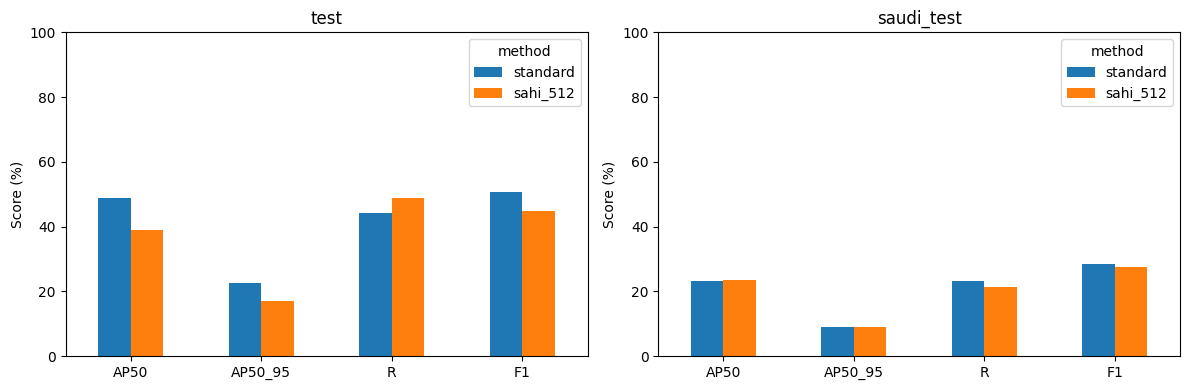

In [8]:
TEST_RECORDS={}; result_rows=[]; error_rows=[]
for split in ['test','saudi_test']:
    for method in ['standard',SAHI_METHOD]:
        records=collect(PATHS[split],split,method); TEST_RECORDS[split,method]=records
        thresholds=np.asarray(OPTIONS[method]['thresholds'])
        ap=ap_scores(records); point=operating(records,thresholds)
        exact=[]
        for rec in records:
            pred=rec['pred']; keep=pred[:,4]>=thresholds[pred[:,5].astype(int)]
            true_classes=set(rec['truth'][:,0].astype(int))
            pred_classes=set(pred[keep,5].astype(int))
            exact.append(true_classes==pred_classes)
            flags=match(rec['truth'],pred)[:,0]; tp=int(flags[keep].sum())
            error_rows.append(dict(split=split,method=method,image=rec['image'],
                TP=tp,FP=int(keep.sum())-tp,FN=len(rec['truth'])-tp))
        for c in range(NC):
            result_rows.append(dict(split=split,method=method,code=CODES[c],
                AP50=float(ap[c,0]),AP50_95=float(ap[c].mean()),
                **{k:float(point[k][c]) for k in ['P','R','F1','TP','FP','FN']}))
        result_rows.append(dict(split=split,method=method,code='MACRO',
            AP50=float(ap[:,0].mean()),AP50_95=float(ap.mean()),
            P=float(point['P'].mean()),R=float(point['R'].mean()),F1=float(point['F1'].mean()),
            TP=int(point['TP'].sum()),FP=int(point['FP'].sum()),FN=int(point['FN'].sum()),
            image_exact_match=float(np.mean(exact)),images=len(records)))
results=pd.DataFrame(result_rows)
results.to_csv(OUTPUT/'final_metrics.csv',index=False)
errors=pd.DataFrame(error_rows); errors.to_csv(OUTPUT/'image_errors.csv',index=False)
summary=results[results.code=='MACRO'].copy(); display(summary.round(4))
deltas=[]
for split in ['test','saudi_test']:
    table=summary[summary.split==split].set_index('method')
    deltas.append(dict(split=split,**{metric+'_change_pp':100*(table.loc[SAHI_METHOD,metric]-table.loc['standard',metric])
        for metric in ['AP50','AP50_95','P','R','F1','image_exact_match']}))
delta_table=pd.DataFrame(deltas); delta_table.to_csv(OUTPUT/'sahi_vs_standard_delta.csv',index=False)
print('Measured SAHI minus standard, in percentage points:'); display(delta_table.round(2))
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,split in zip(axes,['test','saudi_test']):
    table=summary[summary.split==split].set_index('method')[['AP50','AP50_95','R','F1']]*100
    table.T.plot.bar(ax=ax,rot=0); ax.set(title=split,ylabel='Score (%)',ylim=(0,100))
fig.tight_layout(); fig.savefig(OUTPUT/'paired_test_comparison.png',dpi=160); plt.show()


## 7. Inspect the same Saudi examples for both methods
Green boxes are ground truth. Cyan boxes are predictions above frozen thresholds.
Examples include a fixed random sample and the worst missed-damage examples for the
selected method. These images explain failures; they must not drive another threshold
search on the same test set. Nothing is silently excluded or relabeled.


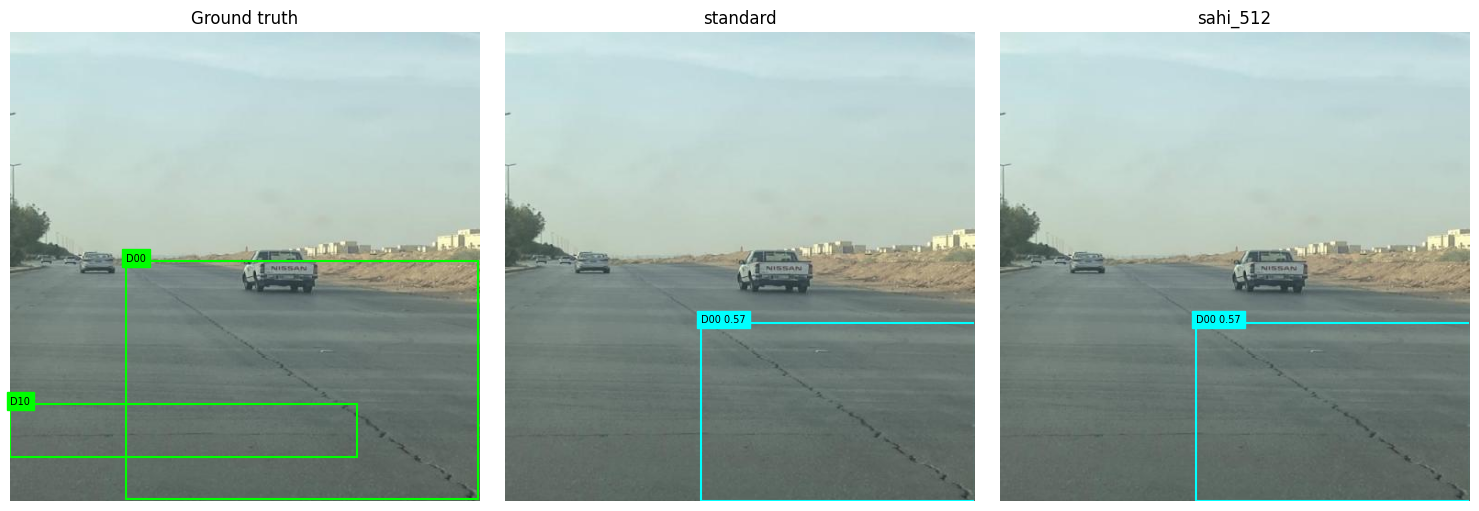

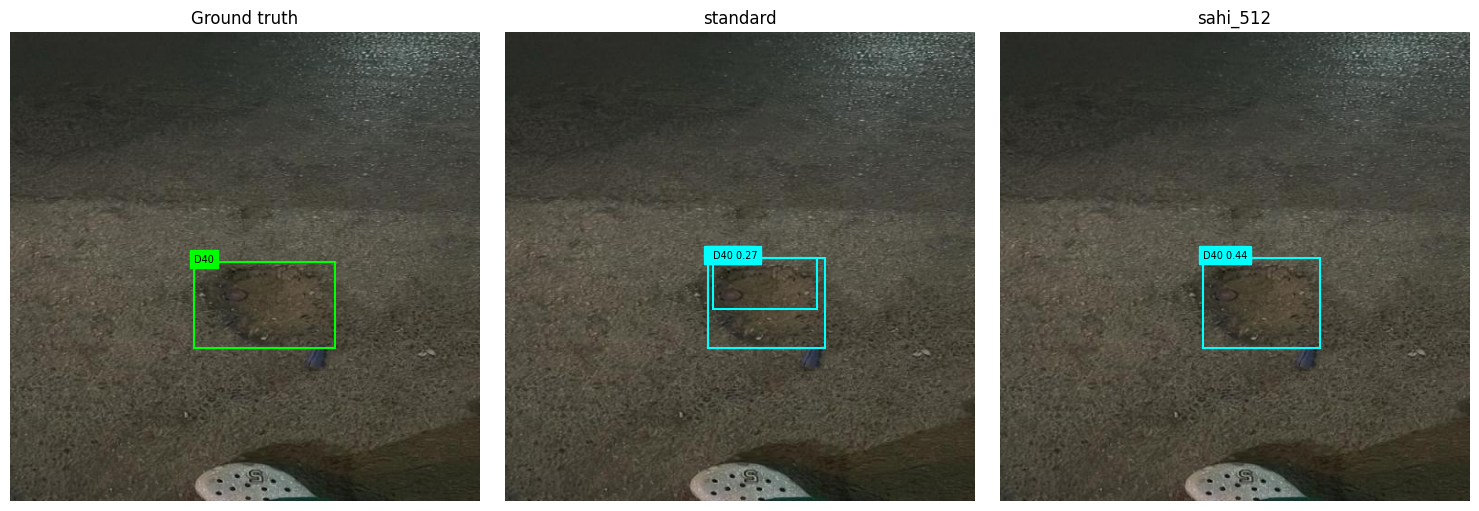

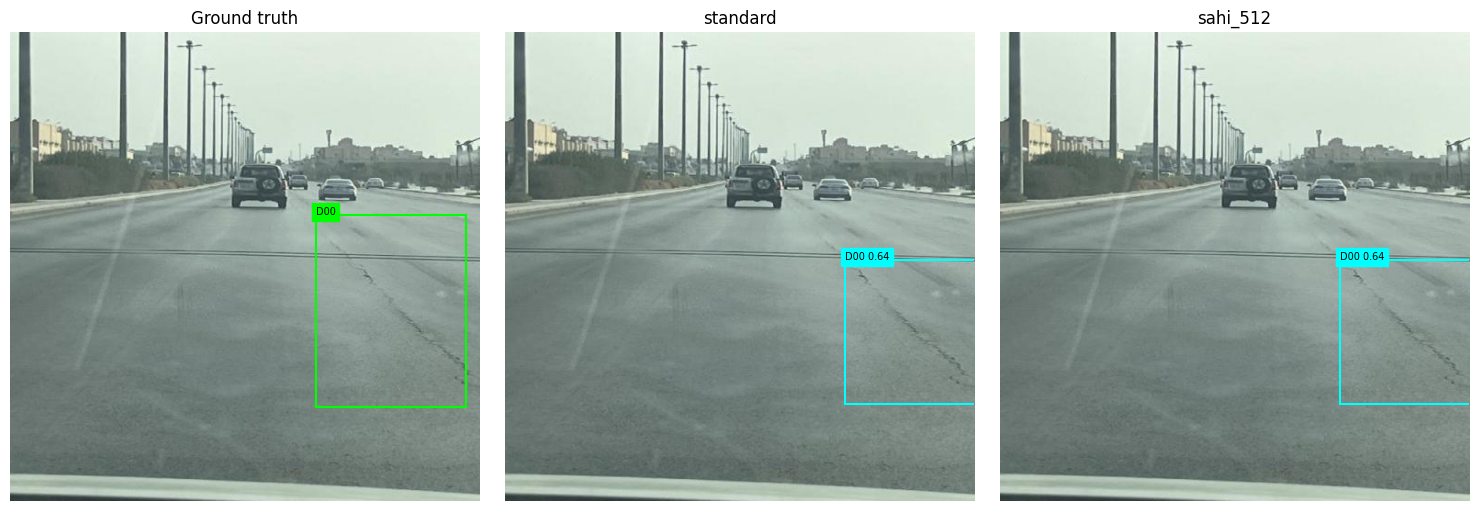

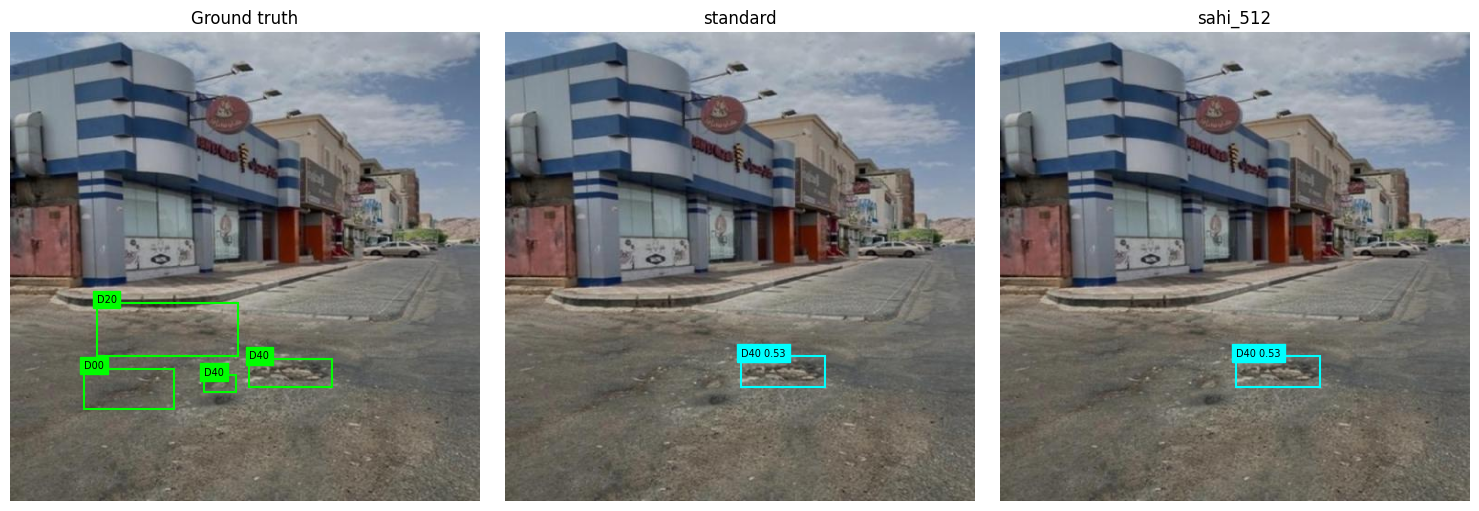

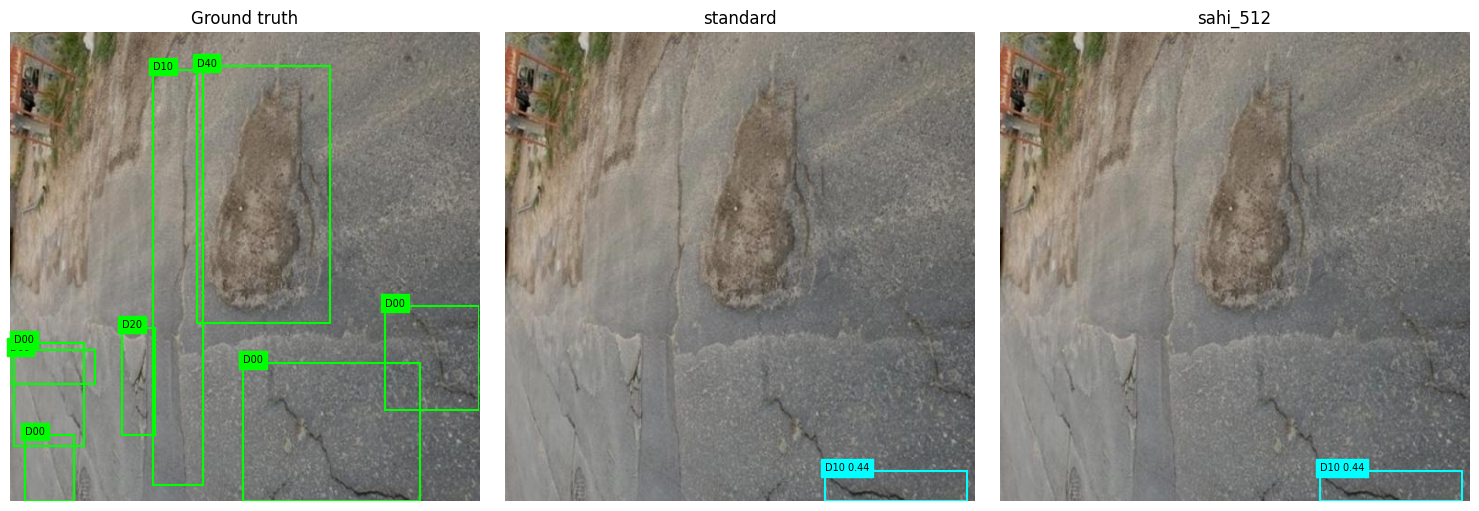

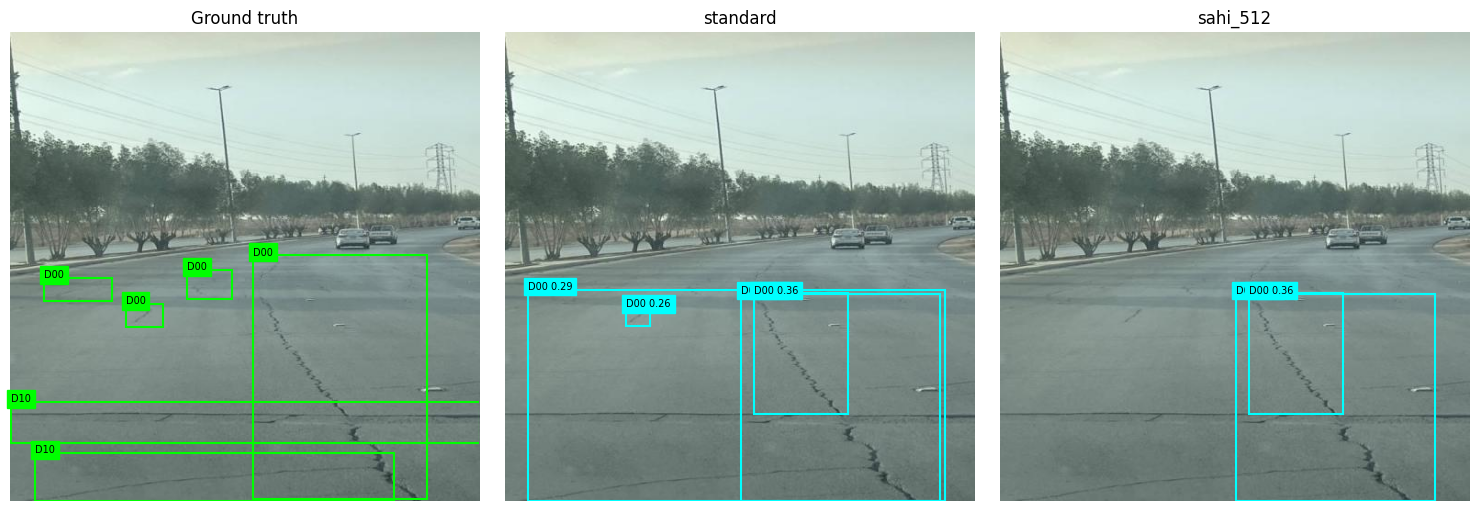

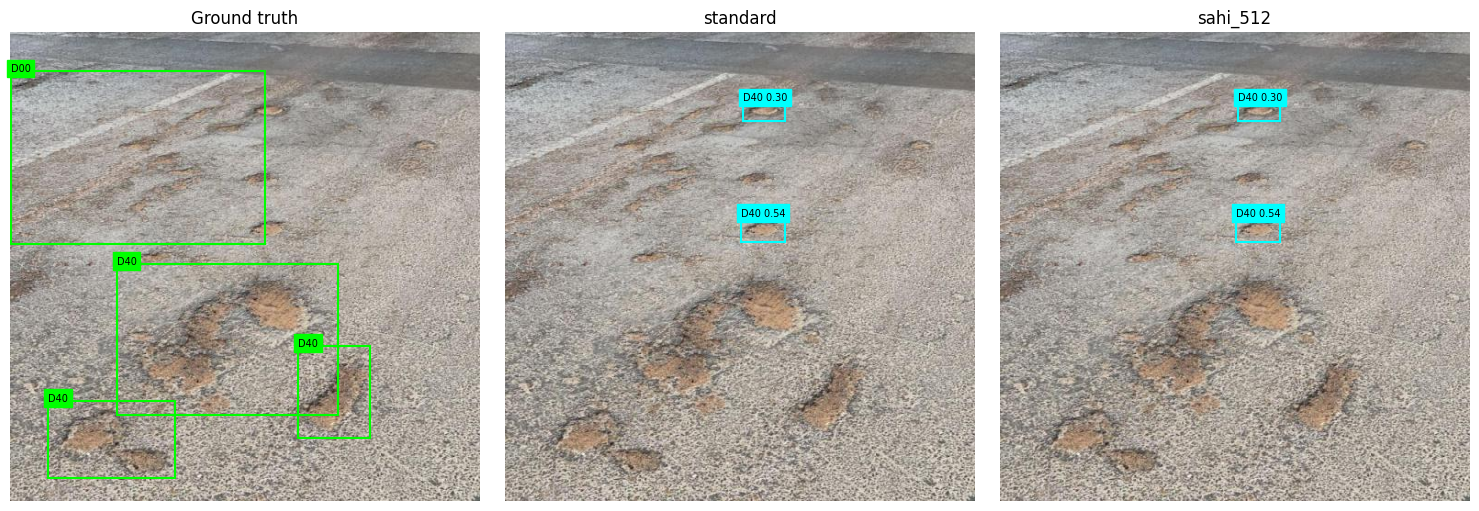

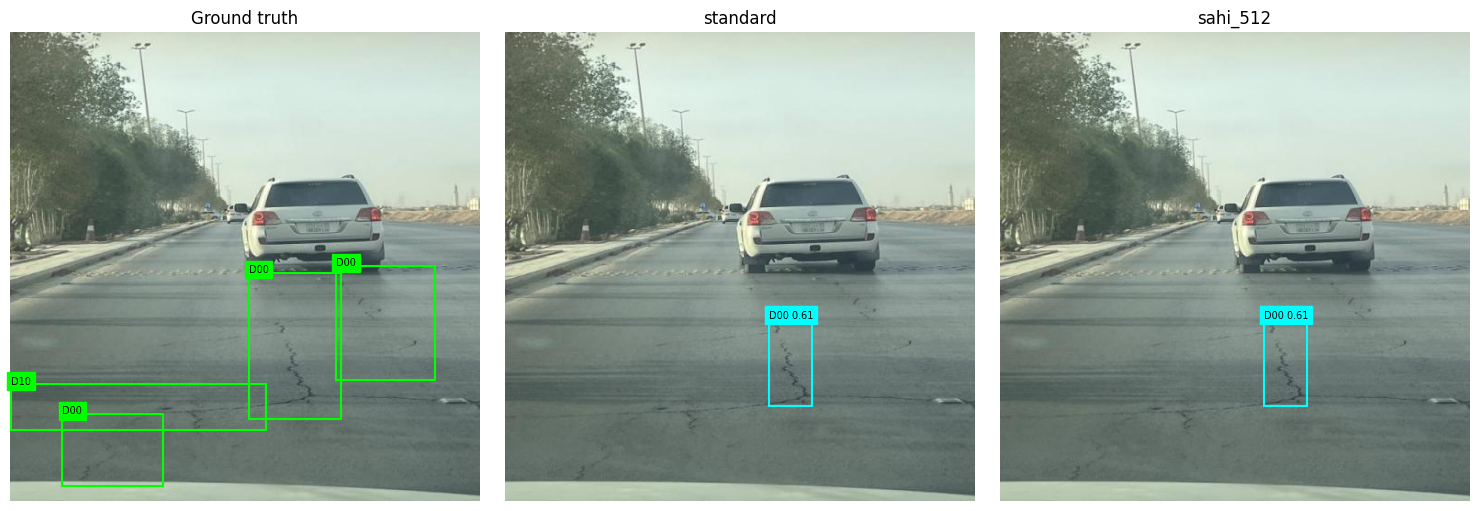

In [14]:
def draw(ax,boxes,predicted=False):
    for box in boxes:
        if predicted: x1,y1,x2,y2,conf,c=box
        else: c,x1,y1,x2,y2=box
        color='cyan' if predicted else 'lime'
        ax.add_patch(plt.Rectangle((x1,y1),x2-x1,y2-y1,fill=False,color=color,lw=1.5))
        text=CODES[int(c)]+(f' {conf:.2f}' if predicted else '')
        ax.text(x1,y1,text,color='black',backgroundcolor=color,fontsize=7)

visual=OUTPUT/'visual_review'; visual.mkdir(exist_ok=True)
lookup={m:{r['image']:r for r in TEST_RECORDS['saudi_test',m]} for m in ['standard',SAHI_METHOD]}
names=list(lookup['standard'])
chosen=random.Random(SEED).sample(names,min(4,len(names)))
worst=errors[(errors.split=='saudi_test')&(errors.method==SELECTED)].sort_values(['FN','FP'],ascending=False)
chosen=list(dict.fromkeys(chosen+worst.image.head(4).tolist()))
for index,name in enumerate(chosen):
    fig,axes=plt.subplots(1,3,figsize=(15,5))
    with Image.open(name) as im: image=np.asarray(im.convert('RGB'))
    for ax in axes: ax.imshow(image); ax.axis('off')
    draw(axes[0],lookup['standard'][name]['truth']); axes[0].set_title('Ground truth')
    for ax,method in zip(axes[1:],['standard',SAHI_METHOD]):
        pred=lookup[method][name]['pred']; thresholds=np.array(OPTIONS[method]['thresholds'])
        draw(ax,pred[pred[:,4]>=thresholds[pred[:,5].astype(int)]],True); ax.set_title(method)
    fig.tight_layout(); fig.savefig(visual/f'comparison_{index:02d}.png',dpi=130)
    plt.show(); plt.close(fig)


## 8. Paired CPU latency and export
Warm up both methods, then time the same 10 validation images without the cache.
This includes image loading, inference, merging and threshold filtering, but excludes
weight loading and plotting. It is distinct from the previous 30-image CPU benchmark.
Export both weights and the selected inference settings; export never triggers training.


In [15]:
CPU_SAMPLE=random.Random(SEED).sample(PATHS['val'],min(10,len(PATHS['val'])))
original_device=DEVICE; DEVICE='cpu'
sliced_model.set_device('cpu')
latency_rows=[]
for method in ['standard',SAHI_METHOD]:
    for _ in range(2): infer(CPU_SAMPLE[0],method)
    durations=[]
    for path in tqdm(CPU_SAMPLE,desc=f'CPU timing: {method}'):
        start=time.perf_counter(); pred=infer(path,method)
        thresholds=np.array(OPTIONS[method]['thresholds'])
        pred=pred[pred[:,4]>=thresholds[pred[:,5].astype(int)]]
        durations.append(1000*(time.perf_counter()-start))
    latency_rows.append(dict(method=method,mean_ms=float(np.mean(durations)),
        median_ms=float(np.median(durations)),p95_ms=float(np.percentile(durations,95)),
        images=len(durations),threads=torch.get_num_threads(),processor=platform.processor()))
DEVICE=original_device; sliced_model.set_device(DEVICE)
latency=pd.DataFrame(latency_rows); latency.to_csv(OUTPUT/'cpu_latency.csv',index=False); display(latency)

PACKAGE=OUTPUT/'deployment_package'; PACKAGE.mkdir(exist_ok=True)
shutil.copy2(WEIGHTS,PACKAGE/'roadscan_best.pt')
export_config={**FROZEN,'class_names':CLASS_NAMES,'codes':CODES,
    'overlap':OVERLAP,'imgsz':IMGSZ,'max_det':MAX_DET,'nms_iou':NMS_IOU,
    'confidence_floor':CONF_FLOOR}
save_json(PACKAGE/'deployment_config.json',export_config)
(PACKAGE/'requirements.txt').write_text('ultralytics==8.4.183\nsahi==0.11.36\nnumpy\n',encoding='utf-8')
for name in ['protocol.json','exclusions.json','validation_screen.csv','validation_full.csv',
             'final_metrics.csv','image_errors.csv','sahi_vs_standard_delta.csv',
             'paired_test_comparison.png','cpu_latency.csv','frozen_selection.json']:
    shutil.copy2(OUTPUT/name,PACKAGE/name)
shutil.copytree(visual,PACKAGE/'visual_review',dirs_exist_ok=True)
print('Selected method:',SELECTED)
print('Test results do not alter the frozen selection. Check recall, false positives and CPU cost together.')


CPU timing: standard:   0%|          | 0/10 [00:00<?, ?it/s]

CPU timing: sahi_512:   0%|          | 0/10 [00:00<?, ?it/s]

,method,mean_ms,median_ms,p95_ms,images,threads,processor
0,standard,199.972592,196.959596,215.546566,10,1,x86_64
1,sahi_512,1404.529158,1325.866520,1801.380239,10,1,x86_64


Selected method: standard
Test results do not alter the frozen selection. Check recall, false positives and CPU cost together.


In [16]:
# Standalone inference helper included with the deployment package.
predict_source = r"""
import json
from pathlib import Path
import numpy as np
from ultralytics import YOLO
from sahi import AutoDetectionModel
from sahi.predict import get_sliced_prediction

class RoadScan:
    def __init__(self, folder, device='cpu'):
        folder=Path(folder)
        self.config=json.loads((folder/'deployment_config.json').read_text())
        self.device=device
        path=str(folder/'roadscan_best.pt')
        c=self.config
        self.model=YOLO(path)
        self.sliced=None
        if c['method']!='standard':
            self.sliced=AutoDetectionModel.from_pretrained(model_type='ultralytics',
                model_path=path,device=device,image_size=c['imgsz'],
                confidence_threshold=c['confidence_floor'])
            self.sliced.model.overrides.update(iou=c['nms_iou'],max_det=c['max_det'])

    def predict(self,image):
        c=self.config
        if self.sliced is None:
            result=self.model.predict(str(image),device=self.device,imgsz=c['imgsz'],
                conf=c['confidence_floor'],iou=c['nms_iou'],max_det=c['max_det'],
                augment=False,verbose=False)[0]
            pred=result.boxes.data.cpu().numpy()[:,:6]
        else:
            tile=c['settings']['tile']
            result=get_sliced_prediction(str(image),self.sliced,slice_height=tile,
                slice_width=tile,overlap_height_ratio=c['overlap'],overlap_width_ratio=c['overlap'],
                perform_standard_pred=True,postprocess_type='NMS',postprocess_match_metric='IOU',
                postprocess_match_threshold=c['nms_iou'],postprocess_class_agnostic=False,verbose=0)
            pred=np.asarray([p.bbox.to_xyxy()+[p.score.value,p.category.id]
                for p in result.object_prediction_list],dtype=float).reshape(-1,6)
        pred=pred[np.argsort(-pred[:,4],kind='stable')[:c['max_det']]]
        thresholds=np.asarray(c['thresholds'])
        return pred[pred[:,4]>=thresholds[pred[:,5].astype(int)]]
"""
(PACKAGE/'predict.py').write_text(predict_source,encoding='utf-8')
(PACKAGE/'README.txt').write_text(
    'RoadScan: existing YOLO26n weights, no extra training.\n'
    'Install requirements.txt, then use:\n'
    'from predict import RoadScan\n'
    'detector = RoadScan("/path/to/deployment_package", device="cpu")\n'
    'boxes = detector.predict("image.jpg")\n'
    'Output columns: x1,y1,x2,y2,confidence,class_id.\n'
    'The selected standard/SAHI method and thresholds come from validation only.\n'
    'Review final_metrics.csv and cpu_latency.csv before use. Human review remains necessary.\n',
    encoding='utf-8')
archive=shutil.make_archive(str(OUTPUT/'RoadScan_YOLO26n_SAHI_Deployment'),'zip',root_dir=PACKAGE)
print('Saved to Drive:',archive)
from google.colab import files
files.download(archive)


Saved to Drive: /content/drive/MyDrive/RoadScan_P/RoadScan_SAHI_Evaluation/RoadScan_YOLO26n_SAHI_Deployment.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Interpretation and next steps
- A positive SAHI delta means a measured gain on that split; negative means a loss.
- A lower confidence threshold may improve recall while reducing precision. It does not retrain the model.
- SAHI is selected only by the full-validation rule, not by Saudi test performance.
- If SAHI loses or is too slow, keep standard YOLO and continue priority scoring and duplicate detection.
- Persistent weak Saudi recall calls for independently collected, consistently annotated local data
  and a separate future training/validation/test experiment. Do not train on these 77 test images.
- This is a focused detector improvement notebook, not all Track A deliverables.

References: [SAHI](https://obss.github.io/sahi/),
[Ultralytics AP metrics](https://docs.ultralytics.com/reference/utils/metrics/).
